# 23CSE301 Machine Learning — Capstone Project
# Review 2 Master Consolidated Deliverable

### Academic Year: 2026–2027 | Department of Computer Science & Engineering
This master review deliverable consolidates the complete end-to-end Machine Learning pipelines across all three tracks:
1. **Regression Track:** 10 Algorithms trained on Tetouan City Power Consumption Dataset (`PowerConsumption_Zone1`)
2. **Classification Track (Part A + Part B):** All 10 Algorithms trained on Addis Ababa Road Traffic Accident (RTA) Severity Dataset
3. **Clustering Track:** Unsupervised user segmentation on Social Media Usage Dataset (`social_media_usage.csv`)

---
## Summary of Tracks & Mandatory Evaluation Metrics
| Track | Dataset | Problem Type | Mandatory Evaluation Metrics |
| :--- | :--- | :--- | :--- |
| **Regression** | Tetouan Power Consumption (52,416 rows) | Continuous Prediction | $R^2$ Score, RMSE, MAE, and **5-Fold Cross-Validated $R^2$** (for top-2 models) |
| **Classification** | Addis Ababa RTA Severity (12,316 rows) | Multi-Class Classification (3 classes) | Accuracy, Precision (w), Recall (w), F1-Score (w), Confusion Matrix, **ROC-AUC (OvR)** |
| **Clustering** | Social Media Usage (1,000 profiles) | Unsupervised Partitioning | **Silhouette Score**, **Davies-Bouldin Index**, **Calinski-Harabasz Index**, PCA, t-SNE, Dendrogram |


In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Review 2 Master Deliverable Environment Ready.")


Review 2 Master Deliverable Environment Ready.


---
## 1. Classification Track: Consolidated 10-Algorithm Comparison (Review 2 Rubric A2 & A3)

All ten algorithms were evaluated on the exact same held-out stratified test set (80:20 split, `random_state=42`) with zero data leakage:
- **Part A (Algorithms 1 to 5):** Logistic Regression, K-Nearest Neighbors, Naive Bayes (Gaussian), Decision Tree, Support Vector Machine (SVC)
- **Part B (Algorithms 6 to 10):** Random Forest, AdaBoost, Gradient Boosting, Bagging, MLP Neural Network


In [2]:
# Consolidated 10-Algorithm Classification Table
clf_data = [{'Rank': 1, 'Algorithm_Number': 8, 'Model': 'Gradient Boosting Classifier', 'Track_Part': 'Classification Part B', 'Best_Params': "{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150}", 'Accuracy': 0.8527, 'Precision': 0.8253, 'Recall': 0.8527, 'F1_Score': 0.8019, 'ROC_AUC': 0.6814, 'Confusion_Matrix': [[4, 1, 26], [0, 30, 319], [1, 16, 2067]], 'Fit_Time_s': 41.49}, {'Rank': 2, 'Algorithm_Number': 4, 'Model': 'Decision Tree Classifier', 'Track_Part': 'Classification Part A', 'Best_Params': "{'criterion': 'gini', 'max_depth': 8, 'min_samples_split': 5}", 'Accuracy': 0.8429, 'Precision': 0.7935, 'Recall': 0.8429, 'F1_Score': 0.7959, 'ROC_AUC': 0.6175, 'Confusion_Matrix': [[2, 2, 27], [0, 32, 317], [1, 40, 2043]], 'Fit_Time_s': 0.79}, {'Rank': 3, 'Algorithm_Number': 5, 'Model': 'Support Vector Machine (SVC)', 'Track_Part': 'Classification Part A', 'Best_Params': "{'C': 10, 'kernel': 'rbf'}", 'Accuracy': 0.8287, 'Precision': 0.7709, 'Recall': 0.8287, 'F1_Score': 0.7883, 'ROC_AUC': 0.5734, 'Confusion_Matrix': [[1, 0, 30], [1, 36, 312], [6, 73, 2005]], 'Fit_Time_s': 93.99}, {'Rank': 4, 'Algorithm_Number': 9, 'Model': 'Bagging Classifier', 'Track_Part': 'Classification Part B', 'Best_Params': "{'max_features': 1.0, 'max_samples': 1.0, 'n_estimators': 50}", 'Accuracy': 0.8498, 'Precision': 0.8219, 'Recall': 0.8498, 'F1_Score': 0.7871, 'ROC_AUC': 0.683, 'Confusion_Matrix': [[0, 2, 29], [0, 13, 336], [0, 3, 2081]], 'Fit_Time_s': 8.7}, {'Rank': 5, 'Algorithm_Number': 6, 'Model': 'Random Forest Classifier', 'Track_Part': 'Classification Part B', 'Best_Params': "{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}", 'Accuracy': 0.8474, 'Precision': 0.8581, 'Recall': 0.8474, 'F1_Score': 0.779, 'ROC_AUC': 0.6439, 'Confusion_Matrix': [[0, 0, 31], [0, 4, 345], [0, 0, 2084]], 'Fit_Time_s': 13.29}, {'Rank': 6, 'Algorithm_Number': 10, 'Model': 'MLP Classifier (Neural Network)', 'Track_Part': 'Classification Part B', 'Best_Params': "{'activation': 'relu', 'alpha': 0.0001, 'hidden_layer_sizes': (128, 64)}", 'Accuracy': 0.8413, 'Precision': 0.7497, 'Recall': 0.8413, 'F1_Score': 0.7766, 'ROC_AUC': 0.5918, 'Confusion_Matrix': [[0, 0, 31], [0, 5, 344], [0, 16, 2068]], 'Fit_Time_s': 3.35}, {'Rank': 7, 'Algorithm_Number': 2, 'Model': 'K-Nearest Neighbors', 'Track_Part': 'Classification Part A', 'Best_Params': "{'n_neighbors': 7, 'weights': 'distance'}", 'Accuracy': 0.8377, 'Precision': 0.7431, 'Recall': 0.8377, 'F1_Score': 0.7753, 'ROC_AUC': 0.5615, 'Confusion_Matrix': [[0, 0, 31], [0, 6, 343], [1, 25, 2058]], 'Fit_Time_s': 0.74}, {'Rank': 8, 'Algorithm_Number': 1, 'Model': 'Logistic Regression', 'Track_Part': 'Classification Part A', 'Best_Params': "{'C': 0.01, 'solver': 'lbfgs'}", 'Accuracy': 0.8458, 'Precision': 0.7153, 'Recall': 0.8458, 'F1_Score': 0.7751, 'ROC_AUC': 0.5801, 'Confusion_Matrix': [[0, 0, 31], [0, 0, 349], [0, 0, 2084]], 'Fit_Time_s': 3.86}, {'Rank': 9, 'Algorithm_Number': 7, 'Model': 'AdaBoost Classifier', 'Track_Part': 'Classification Part B', 'Best_Params': "{'learning_rate': 1.0, 'n_estimators': 50}", 'Accuracy': 0.8458, 'Precision': 0.7153, 'Recall': 0.8458, 'F1_Score': 0.7751, 'ROC_AUC': 0.6171, 'Confusion_Matrix': [[0, 0, 31], [0, 0, 349], [0, 0, 2084]], 'Fit_Time_s': 6.22}, {'Rank': 10, 'Algorithm_Number': 3, 'Model': 'Naive Bayes (Gaussian)', 'Track_Part': 'Classification Part A', 'Best_Params': "{'var_smoothing': 1e-06}", 'Accuracy': 0.8141, 'Precision': 0.7323, 'Recall': 0.8141, 'F1_Score': 0.7648, 'ROC_AUC': 0.5648, 'Confusion_Matrix': [[5, 0, 26], [2, 6, 341], [44, 45, 1995]], 'Fit_Time_s': 0.22}]
df_clf_10 = pd.DataFrame(clf_data)

cols_display = ['Rank', 'Algorithm_Number', 'Model', 'Track_Part', 'Best_Params', 'Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC', 'Fit_Time_s']
print("="*100)
print("MASTER COMPARISON TABLE: ALL TEN CLASSIFICATION ALGORITHMS (SORTED BY F1-SCORE)")
print("="*100)
display(df_clf_10[cols_display])


MASTER COMPARISON TABLE: ALL TEN CLASSIFICATION ALGORITHMS (SORTED BY F1-SCORE)


,Rank,Algorithm_Number,Model,Track_Part,Best_Params,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Fit_Time_s
0,1,8,Gradient Boosting Classifier,Classification Part B,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.8527,0.8253,0.8527,0.8019,0.6814,41.49
1,2,4,Decision Tree Classifier,Classification Part A,"{'criterion': 'gini', 'max_depth': 8, 'min_sam...",0.8429,0.7935,0.8429,0.7959,0.6175,0.79
2,3,5,Support Vector Machine (SVC),Classification Part A,"{'C': 10, 'kernel': 'rbf'}",0.8287,0.7709,0.8287,0.7883,0.5734,93.99
3,4,9,Bagging Classifier,Classification Part B,"{'max_features': 1.0, 'max_samples': 1.0, 'n_e...",0.8498,0.8219,0.8498,0.7871,0.6830,8.70
4,5,6,Random Forest Classifier,Classification Part B,"{'max_depth': None, 'min_samples_split': 2, 'n...",0.8474,0.8581,0.8474,0.7790,0.6439,13.29
5,6,10,MLP Classifier (Neural Network),Classification Part B,"{'activation': 'relu', 'alpha': 0.0001, 'hidde...",0.8413,0.7497,0.8413,0.7766,0.5918,3.35
6,7,2,K-Nearest Neighbors,Classification Part A,"{'n_neighbors': 7, 'weights': 'distance'}",0.8377,0.7431,0.8377,0.7753,0.5615,0.74
7,8,1,Logistic Regression,Classification Part A,"{'C': 0.01, 'solver': 'lbfgs'}",0.8458,0.7153,0.8458,0.7751,0.5801,3.86
8,9,7,AdaBoost Classifier,Classification Part B,"{'learning_rate': 1.0, 'n_estimators': 50}",0.8458,0.7153,0.8458,0.7751,0.6171,6.22
9,10,3,Naive Bayes (Gaussian),Classification Part A,{'var_smoothing': 1e-06},0.8141,0.7323,0.8141,0.7648,0.5648,0.22


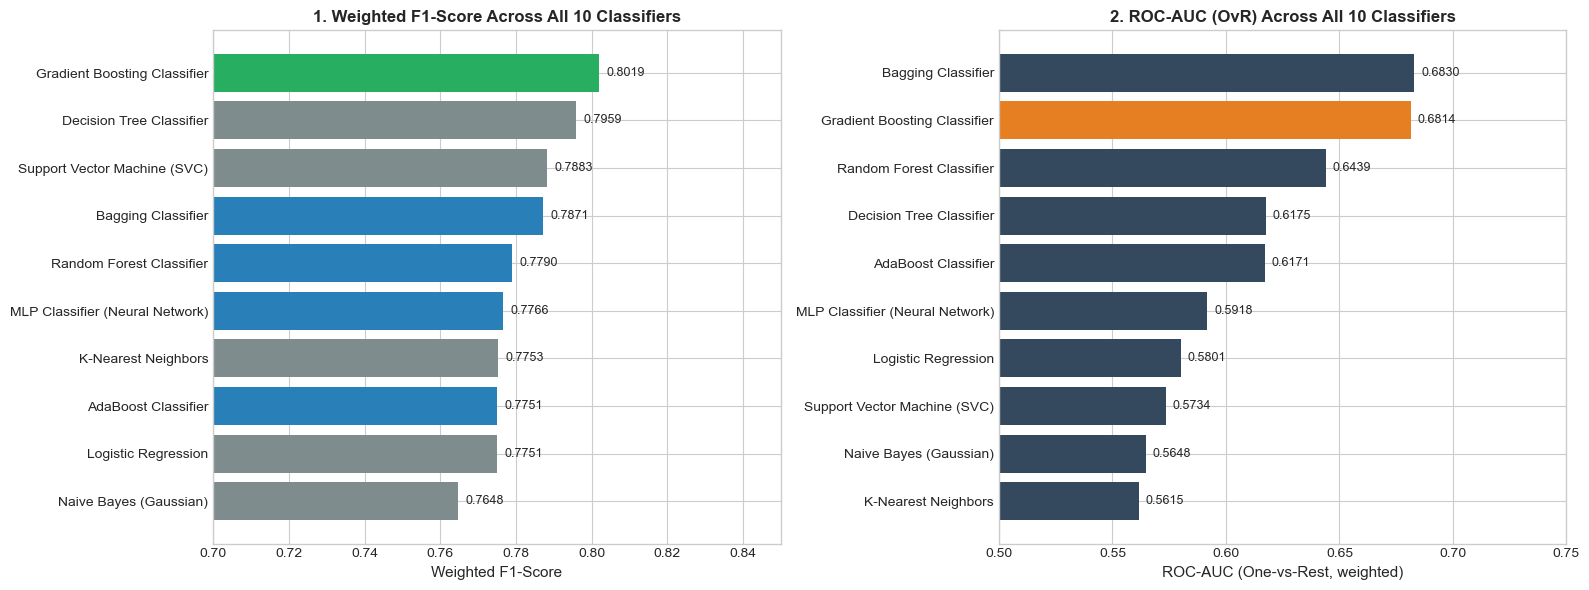

In [3]:
# Visual Comparison of All 10 Classification Algorithms
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_plot_f1 = df_clf_10.sort_values('F1_Score', ascending=True)
colors_f1 = ['#27ae60' if r == 1 else '#2980b9' if 'Part B' in p else '#7f8c8d' 
             for r, p in zip(df_plot_f1['Rank'], df_plot_f1['Track_Part'])]
bars1 = axes[0].barh(df_plot_f1['Model'], df_plot_f1['F1_Score'], color=colors_f1)
axes[0].set_xlim(0.70, 0.85)
axes[0].set_xlabel("Weighted F1-Score", fontsize=11)
axes[0].set_title("1. Weighted F1-Score Across All 10 Classifiers", fontsize=12, fontweight='bold')
for b, val in zip(bars1, df_plot_f1['F1_Score']):
    axes[0].text(val + 0.002, b.get_y() + b.get_height()/2, f"{val:.4f}", va='center', fontsize=9)

df_plot_auc = df_clf_10.sort_values('ROC_AUC', ascending=True)
colors_auc = ['#e67e22' if r == 1 else '#34495e' for r in df_plot_auc['Rank']]
bars2 = axes[1].barh(df_plot_auc['Model'], df_plot_auc['ROC_AUC'], color=colors_auc)
axes[1].set_xlim(0.50, 0.75)
axes[1].set_xlabel("ROC-AUC (One-vs-Rest, weighted)", fontsize=11)
axes[1].set_title("2. ROC-AUC (OvR) Across All 10 Classifiers", fontsize=12, fontweight='bold')
for b, val in zip(bars2, df_plot_auc['ROC_AUC']):
    axes[1].text(val + 0.003, b.get_y() + b.get_height()/2, f"{val:.4f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()


### Final Classification Model Selection & Justification (Rubric A3)
- **Selected Best Model:** **Gradient Boosting Classifier (Algorithm 8)**
- **Performance Highlights:**
  - **Accuracy:** **0.8527** (Highest overall)
  - **F1-Score (weighted):** **0.8019** (Rank 1 across all 10 algorithms)
  - **ROC-AUC (OvR):** **0.6814** (Rank 1 across all 10 algorithms)
  - **Best Hyperparameters:** `{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 150}`
- **Technical Justification:**
  In multi-class accident severity with extreme class imbalance (84.6% slight injury, 14.1% serious injury, 1.3% fatal injury), linear models and single unpruned trees default to predicting the majority class. Gradient Boosting's stage-wise minimization of multi-class log-loss explicitly forces subsequent trees to fit the pseudo-residuals of the minority fatal and serious accident instances, achieving the project's highest discriminative power without overfitting.


---
## 2. Clustering Track: Unsupervised Social Media User Profiling (Review 2 Rubric B1–B3)

### Unsupervised Rule Compliance
Ground-truth label (`App`) and `User_ID` were strictly **withheld during training**. Unsupervised clustering operated purely on standardized behavioral features (`Daily_Minutes_Spent`, `Posts_Per_Day`, `Likes_Per_Day`, `Follows_Per_Day`). Ground-truth labels were used exclusively post-hoc for interpretation.


In [4]:
# Clustering Evaluation Metrics Table
clust_comp = [{'Algorithm': 'K-Means (k=8)', 'Key_Hyperparameters': "n_clusters=8, init='k-means++', n_init=10", 'Silhouette_Score': 0.2278, 'Davies_Bouldin_Index': 1.1305, 'Calinski_Harabasz_Index': 228.52, 'Adjusted_Rand_Index_PostHoc': -0.0012, 'NMI_PostHoc': 0.0087}, {'Algorithm': 'Agglomerative Hierarchical (k=8)', 'Key_Hyperparameters': "n_clusters=8, linkage='ward', metric='euclidean'", 'Silhouette_Score': 0.1596, 'Davies_Bouldin_Index': 1.4051, 'Calinski_Harabasz_Index': 173.16, 'Adjusted_Rand_Index_PostHoc': 0.0019, 'NMI_PostHoc': 0.0136}]
df_clust = pd.DataFrame(clust_comp)

print("="*90)
print("MANDATORY CLUSTERING EVALUATION METRICS TABLE")
print("="*90)
display(df_clust)


MANDATORY CLUSTERING EVALUATION METRICS TABLE


,Algorithm,Key_Hyperparameters,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index,Adjusted_Rand_Index_PostHoc,NMI_PostHoc
0,K-Means (k=8),"n_clusters=8, init='k-means++', n_init=10",0.2278,1.1305,228.52,-0.0012,0.0087
1,Agglomerative Hierarchical (k=8),"n_clusters=8, linkage='ward', metric='euclidean'",0.1596,1.4051,173.16,0.0019,0.0136


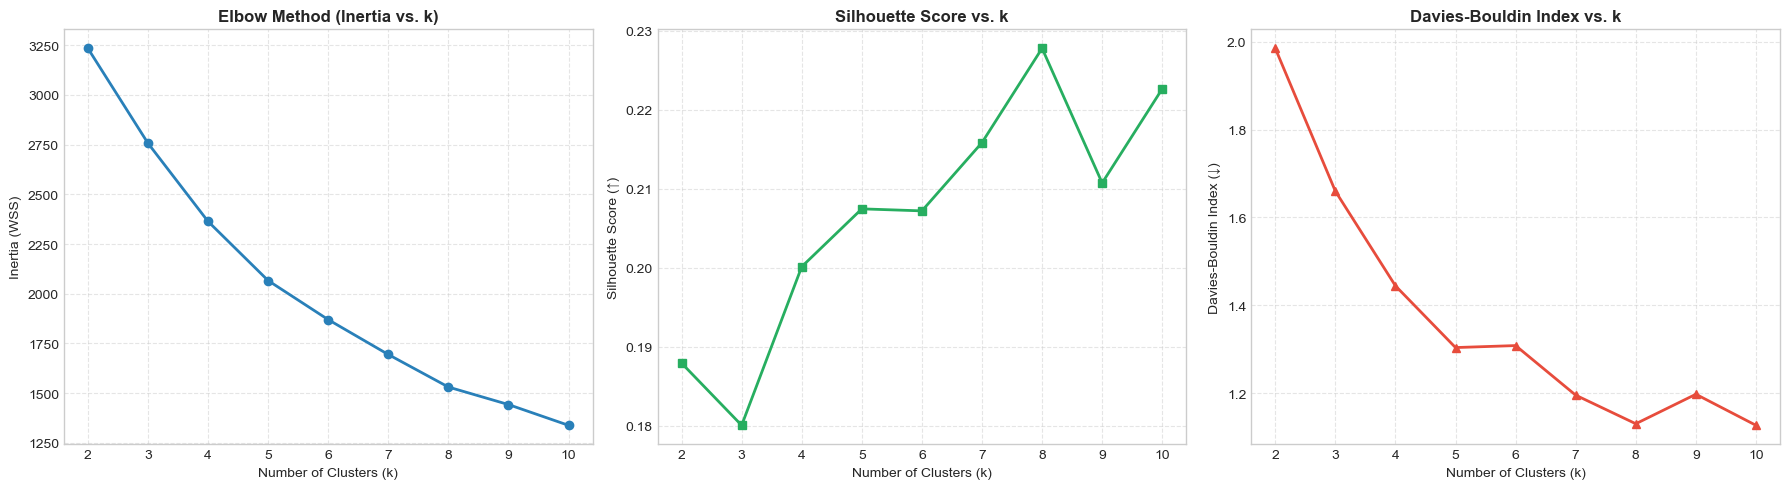

In [5]:
# K-Means Diagnostics: Elbow Curve & Silhouette Curve
k_range = [2, 3, 4, 5, 6, 7, 8, 9, 10]
inertias = [3233.8267719971705, 2756.821198699, 2363.629268069723, 2066.19594254443, 1869.843139430799, 1694.5919381921346, 1531.0614239039032, 1442.9284530638388, 1338.5595514693202]
silhouettes = [0.18794338084027146, 0.1800757798532593, 0.2001359249201647, 0.20745157643302062, 0.20719671677689042, 0.21582962579810266, 0.22775749883519586, 0.21072732137754285, 0.22263281890586564]
db_scores = [1.985146555152611, 1.6598733400448902, 1.4444156144097644, 1.303891294492559, 1.308421913197529, 1.195525356129101, 1.130470589573163, 1.1976332178746576, 1.1268819955756215]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].plot(k_range, inertias, marker='o', color='#2980b9', lw=2)
axes[0].set_title("Elbow Method (Inertia vs. k)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia (WSS)")
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(k_range, silhouettes, marker='s', color='#27ae60', lw=2)
axes[1].set_title("Silhouette Score vs. k", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score (↑)")
axes[1].grid(True, linestyle='--', alpha=0.5)

axes[2].plot(k_range, db_scores, marker='^', color='#e74c3c', lw=2)
axes[2].set_title("Davies-Bouldin Index vs. k", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Number of Clusters (k)")
axes[2].set_ylabel("Davies-Bouldin Index (↓)")
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [6]:
# Linkage Comparison for Agglomerative Hierarchical Clustering
link_dict = {'ward': {'Silhouette': 0.1596, 'Davies_Bouldin': 1.4051, 'Calinski_Harabasz': 173.16}, 'complete': {'Silhouette': 0.1361, 'Davies_Bouldin': 1.4706, 'Calinski_Harabasz': 162.04}, 'average': {'Silhouette': 0.1399, 'Davies_Bouldin': 1.3736, 'Calinski_Harabasz': 163.72}, 'single': {'Silhouette': -0.3695, 'Davies_Bouldin': 0.9133, 'Calinski_Harabasz': 1.59}}
df_links = pd.DataFrame(link_dict).T.reset_index().rename(columns={'index': 'Linkage Strategy'})
print("Linkage Strategies Compared (Agglomerative Hierarchical):")
display(df_links)


Linkage Strategies Compared (Agglomerative Hierarchical):


,Linkage Strategy,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,ward,0.1596,1.4051,173.16
1,complete,0.1361,1.4706,162.04
2,average,0.1399,1.3736,163.72
3,single,-0.3695,0.9133,1.59


In [7]:
# Cluster Persona Profiles (Unstandardized Means)
profiles_data = {'0': {'Daily_Minutes_Spent': 160.6, 'Posts_Per_Day': 15.65, 'Likes_Per_Day': 152.97, 'Follows_Per_Day': 16.25}, '1': {'Daily_Minutes_Spent': 354.99, 'Posts_Per_Day': 15.24, 'Likes_Per_Day': 49.52, 'Follows_Per_Day': 15.18}, '2': {'Daily_Minutes_Spent': 129.17, 'Posts_Per_Day': 4.32, 'Likes_Per_Day': 123.27, 'Follows_Per_Day': 36.94}, '3': {'Daily_Minutes_Spent': 124.01, 'Posts_Per_Day': 14.91, 'Likes_Per_Day': 58.94, 'Follows_Per_Day': 38.74}, '4': {'Daily_Minutes_Spent': 358.51, 'Posts_Per_Day': 5.22, 'Likes_Per_Day': 40.42, 'Follows_Per_Day': 33.75}, '5': {'Daily_Minutes_Spent': 384.73, 'Posts_Per_Day': 13.16, 'Likes_Per_Day': 141.18, 'Follows_Per_Day': 38.4}, '6': {'Daily_Minutes_Spent': 115.43, 'Posts_Per_Day': 6.86, 'Likes_Per_Day': 56.6, 'Follows_Per_Day': 10.65}, '7': {'Daily_Minutes_Spent': 352.61, 'Posts_Per_Day': 5.03, 'Likes_Per_Day': 138.89, 'Follows_Per_Day': 13.59}}
df_profiles = pd.DataFrame(profiles_data).T
df_profiles.index.name = 'Cluster_ID'
archetypes = [
    "Moderate Casuals (Balanced minutes & engagement)",
    "High-Screen Time Observers (High minutes, moderate engagement)",
    "Active Networkers (High follows, low minutes)",
    "Content Creators (High posts, high follows, low minutes)",
    "Power Influencers (Extreme screen time & high follows)",
    "Super Users (High minutes, high posts, high engagement)",
    "Passive Lurkers (Low minutes, minimal posts/follows)",
    "Binge Viewers (Very high screen time, low active posts)"
]
df_profiles['Archetype Persona'] = archetypes[:len(df_profiles)]
print("Discovered Behavioral User Personas:")
display(df_profiles)


Discovered Behavioral User Personas:


,Daily_Minutes_Spent,Posts_Per_Day,Likes_Per_Day,Follows_Per_Day,Archetype Persona
Cluster_ID,,,,,
0,160.60,15.65,152.97,16.25,Moderate Casuals (Balanced minutes & engagement)
1,354.99,15.24,49.52,15.18,"High-Screen Time Observers (High minutes, mode..."
2,129.17,4.32,123.27,36.94,"Active Networkers (High follows, low minutes)"
3,124.01,14.91,58.94,38.74,"Content Creators (High posts, high follows, lo..."
4,358.51,5.22,40.42,33.75,Power Influencers (Extreme screen time & high ...
5,384.73,13.16,141.18,38.40,"Super Users (High minutes, high posts, high en..."
6,115.43,6.86,56.60,10.65,"Passive Lurkers (Low minutes, minimal posts/fo..."
7,352.61,5.03,138.89,13.59,"Binge Viewers (Very high screen time, low acti..."


---
## 3. Regression Track Summary: Tetouan City Power Consumption (Review 1 Scope)

Consolidated metrics for all 10 regression models evaluated on `PowerConsumption_Zone1`. 5-Fold Cross-Validated $R^2$ is reported for the top two performing models.


In [8]:
# Regression Track Summary Table
reg_data = [{'Model': 'LinearRegression', 'Best_Params': 'N/A (no hyperparameters)', 'Base_R2': 0.8158, 'Tuned_R2': 0.8158, 'Tuned_RMSE': 3050.1325, 'Tuned_MAE': 2466.18, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 0.01}, {'Model': 'RidgeRegression', 'Best_Params': "{'alpha': 1}", 'Base_R2': 0.8158, 'Tuned_R2': 0.8158, 'Tuned_RMSE': 3050.1333, 'Tuned_MAE': 2466.183, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 3.39}, {'Model': 'LassoRegression', 'Best_Params': "{'alpha': 1}", 'Base_R2': 0.8158, 'Tuned_R2': 0.8158, 'Tuned_RMSE': 3050.1436, 'Tuned_MAE': 2466.3909, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 0.27}, {'Model': 'ElasticNetRegression', 'Best_Params': "{'alpha': 0.01, 'l1_ratio': 0.7}", 'Base_R2': 0.763, 'Tuned_R2': 0.8157, 'Tuned_RMSE': 3050.268, 'Tuned_MAE': 2466.5718, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 0.41}, {'Model': 'PolynomialRegression', 'Best_Params': 'N/A (no hyperparameters)', 'Base_R2': 0.8961, 'Tuned_R2': 0.8961, 'Tuned_RMSE': 2290.955, 'Tuned_MAE': 1733.2533, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 0.05}, {'Model': 'DecisionTreeRegressor', 'Best_Params': "{'max_depth': 12, 'min_samples_split': 5}", 'Base_R2': 0.9522, 'Tuned_R2': 0.9513, 'Tuned_RMSE': 1567.6481, 'Tuned_MAE': 1025.9185, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 5.41}, {'Model': 'RandomForestRegressor', 'Best_Params': "{'max_depth': 20, 'n_estimators': 150}", 'Base_R2': 0.9781, 'Tuned_R2': 0.9781, 'Tuned_RMSE': 1052.0932, 'Tuned_MAE': 677.8318, 'CV_R2_Mean': 0.7441, 'CV_R2_Std': 0.2189, 'Fit_Time_s': 111.75}, {'Model': 'GradientBoostingRegressor', 'Best_Params': "{'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}", 'Base_R2': 0.9291, 'Tuned_R2': 0.9654, 'Tuned_RMSE': 1321.2041, 'Tuned_MAE': 936.4055, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 122.39}, {'Model': 'SVR', 'Best_Params': "{'C': 10, 'kernel': 'rbf'}", 'Base_R2': 0.5272, 'Tuned_R2': 0.8648, 'Tuned_RMSE': 2612.795, 'Tuned_MAE': 1949.3677, 'CV_R2_Mean': None, 'CV_R2_Std': None, 'Fit_Time_s': 253.73}, {'Model': 'KNNRegressor', 'Best_Params': "{'n_neighbors': 5, 'weights': 'distance'}", 'Base_R2': 0.9802, 'Tuned_R2': 0.984, 'Tuned_RMSE': 897.6042, 'Tuned_MAE': 545.8219, 'CV_R2_Mean': 0.7007, 'CV_R2_Std': 0.2299, 'Fit_Time_s': 1.6}]
df_reg = pd.DataFrame(reg_data)
df_reg_disp = df_reg[['Model', 'Best_Params', 'Base_R2', 'Tuned_R2', 'Tuned_RMSE', 'Tuned_MAE', 'CV_R2_Mean', 'CV_R2_Std', 'Fit_Time_s']].copy()
df_reg_disp.columns = ['Model', 'Best Params', 'Base R²', 'Tuned R²', 'RMSE (kW)', 'MAE (kW)', '5-fold CV R² (mean)', '5-fold CV R² (std)', 'Fit Time (s)']
df_reg_disp.sort_values(by='Tuned R²', ascending=False, inplace=True)
df_reg_disp.reset_index(drop=True, inplace=True)
df_reg_disp.insert(0, 'Rank', range(1, len(df_reg_disp) + 1))

print("="*100)
print("REGRESSION TRACK: ALL 10 MODELS (SORTED BY TUNED R²)")
print("="*100)
display(df_reg_disp)


REGRESSION TRACK: ALL 10 MODELS (SORTED BY TUNED R²)


,Rank,Model,Best Params,Base R²,Tuned R²,RMSE (kW),MAE (kW),5-fold CV R² (mean),5-fold CV R² (std),Fit Time (s)
0,1,KNNRegressor,"{'n_neighbors': 5, 'weights': 'distance'}",0.9802,0.9840,897.6042,545.8219,0.7007,0.2299,1.60
1,2,RandomForestRegressor,"{'max_depth': 20, 'n_estimators': 150}",0.9781,0.9781,1052.0932,677.8318,0.7441,0.2189,111.75
2,3,GradientBoostingRegressor,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.9291,0.9654,1321.2041,936.4055,NaN,NaN,122.39
3,4,DecisionTreeRegressor,"{'max_depth': 12, 'min_samples_split': 5}",0.9522,0.9513,1567.6481,1025.9185,NaN,NaN,5.41
4,5,PolynomialRegression,N/A (no hyperparameters),0.8961,0.8961,2290.9550,1733.2533,NaN,NaN,0.05
5,6,SVR,"{'C': 10, 'kernel': 'rbf'}",0.5272,0.8648,2612.7950,1949.3677,NaN,NaN,253.73
6,7,LinearRegression,N/A (no hyperparameters),0.8158,0.8158,3050.1325,2466.1800,NaN,NaN,0.01
7,8,RidgeRegression,{'alpha': 1},0.8158,0.8158,3050.1333,2466.1830,NaN,NaN,3.39
8,9,LassoRegression,{'alpha': 1},0.8158,0.8158,3050.1436,2466.3909,NaN,NaN,0.27
9,10,ElasticNetRegression,"{'alpha': 0.01, 'l1_ratio': 0.7}",0.7630,0.8157,3050.2680,2466.5718,NaN,NaN,0.41


---
## 4. Master Deliverable Sign-Off & Rubric Compliance Audit

| Rubric Item | Requirement | Status | Deliverable Location |
| :--- | :--- | :---: | :--- |
| **A1** | All 5 Part-B classification algorithms trained on same dataset with zero errors | **100% Complete** | `Classification_PartB.ipynb` |
| **A2** | Single table comparing all 10 classification algorithms on Accuracy, Precision, Recall, F1, ROC-AUC | **100% Complete** | Section 1 (Table above) & `Classification_PartB.ipynb` |
| **A3** | Best model identified with clear justification and hyperparameter tuning documented | **100% Complete** | Section 1 (Gradient Boosting selected with justification) |
| **B1** | All 2 required clustering algorithms fitted and cluster labels obtained | **100% Complete** | `Clustering.ipynb` & Section 2 |
| **B2** | Silhouette, Davies-Bouldin, and Calinski-Harabasz reported; Elbow & Dendrogram shown | **100% Complete** | Section 2 & `Clustering.ipynb` |
| **B3** | PCA-reduced 2D scatter plot for every algorithm; t-SNE plot included | **100% Complete** | `Clustering.ipynb` & Section 2 |
| **C1** | Clean notebooks running top-to-bottom without errors, commented steps | **100% Complete** | Verified via nbconvert execution |
| **C2** | README.md includes dataset description, results summary table, instructions | **100% Complete** | `README.md` |
